In [1]:
import numpy as np
from scipy.io import loadmat
from matplotlib import pyplot as plt
from tqdm.auto import tqdm

import build_speed as bs
import fast_marching as fm
import calculate_errors as ce
import diffusion_estimator as de

c:\Users\mperuzzo\OneDrive - Nexus365\Documents\bottlenecks\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# load data
crop = 'maize'
layers = ["sea"]
dataset = loadmat(f'data/{crop}/raw_data.mat')['raw_data']

dt = 40

# start point
dataset[:,2] = dataset[:,2] - 1
start_point = dataset[np.where(dataset[:,2] == 0)[0][0],:]

In [3]:
diff_estimator = de.DiffusionEstimator(crop, layers)
theta = np.array([-0.2264, -0.5552])
S = diff_estimator.build_speed(theta)
arrival_times = diff_estimator.get_arrival_times(S)
# arrival_times = np.clip(arrival_times, 0, 167)
error = diff_estimator.calculate_error(arrival_times)

In [4]:
np.sqrt(error)

np.float64(1156.301760261561)

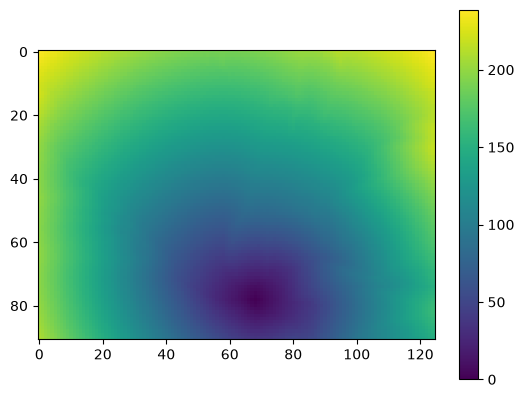

In [5]:
plt.imshow(np.flipud(arrival_times))
plt.colorbar()

In [6]:
# thetas = np.linspace(-1, 1, 11)
# error_matrix = np.zeros((len(thetas), len(thetas)))
# for i, theta1 in enumerate(tqdm(thetas, desc='Evaluating theta')):
#     for j, theta2 in enumerate(thetas):
#         theta = np.array([theta1, theta2])
#         S = bs.build_speed(crop, theta, layers)
#         T = fm.fast_marching(S, [tuple(start_point)])
#         error_matrix[i, j] = ce.calculate_mse(dataset, T, dt)

In [7]:
# theta_mat = np.meshgrid(thetas, thetas)
# plt.imshow(np.flipud(error_matrix) )
# plt.colorbar()
# plt.clim(8e5, 2e6)
# plt.yticks(np.arange(len(thetas)), np.round(theta_mat[1][:,0], 2));
# plt.xticks(np.arange(len(thetas)), np.round(theta_mat[0][0,:], 2));

In [15]:
theta_range = np.array([[-2,-2], [2,2]])
num_points = 21
min_theta, min_error = diff_estimator.sweep_theta(theta_range, num_points)


Evaluating theta combinations: 100%|██████████| 441/441 [01:59<00:00,  3.69it/s]


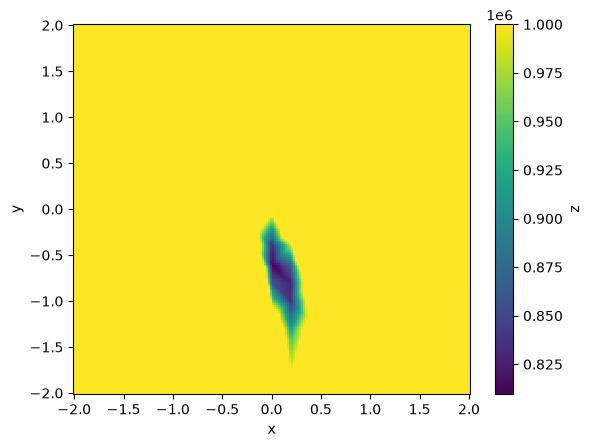

In [25]:
from scipy.interpolate import griddata

# Input scattered points.
x = diff_estimator.objective_function[:, 0]
y = diff_estimator.objective_function[:, 1]
z = diff_estimator.objective_function[:, 2]

# Create a regular plotting grid.
xi = np.linspace(x.min(), x.max(), 200)
yi = np.linspace(y.min(), y.max(), 200)
X, Y = np.meshgrid(xi, yi)

# Interpolate z-values onto the grid.
Z = griddata((x, y), z, (X, Y), method="linear")

# Plot the interpolated surface as a 2D heatmap.
plt.pcolormesh(X, Y, Z, shading="auto", cmap="viridis")
plt.colorbar(label="z")
plt.xlabel("x")
plt.ylabel("y")
plt.clim(Z.min(), 1e6)
plt.show()

In [22]:
21*21

441

In [9]:
result = diff_estimator.fit_theta(min_theta, theta_bounds=[(-2, 2), (-4, 4)])


Iteration 001 | error=807963.632699 | grad_norm=733894.746736 | lr=9.537e-08 | accepted=True | theta=[ 0.  -0.6]
Iteration 002 | error=787046.204770 | grad_norm=146161.094212 | lr=1.907e-07 | accepted=True | theta=[ 0.06942343 -0.5911152 ]
Iteration 003 | error=786041.073541 | grad_norm=155580.808437 | lr=1.907e-07 | accepted=True | theta=[ 0.05144534 -0.61242182]
Iteration 004 | error=785581.411789 | grad_norm=170394.685335 | lr=1.907e-07 | accepted=True | theta=[ 0.08057629 -0.61807646]
Iteration 005 | error=785368.409486 | grad_norm=192046.801518 | lr=9.537e-08 | accepted=True | theta=[ 0.05359962 -0.63620165]
Iteration 006 | error=783702.459045 | grad_norm=44862.393890 | lr=0.0 | accepted=True | theta=[ 0.07190984 -0.63578273]
Final theta: [ 0.07190984 -0.63578273]
Final error: 783702.459045


In [14]:
np.sqrt(result.fun)

np.float64(885.2697097751535)